#**Actividad 2**

###**Maestría en Inteligencia Artificial Aplicada**
###**Curso: Inteligencia Artificial y Aprendizaje Automático**
####**Tecnológico de Monterrey**
#####**Prof Luis Eduardo Falcón Morales**

###**Nombre del estudiante: Brian Ivan Sanciprian Servin**

###**Matrícula: A01374634**

**NOTAS:**

*   Esta actividad la puedes realizar en Google-Colab.
*   Usaremos un conjunto de datos bastante conocido, llamado California_Housing o California_Housing_Prices. El objetivo en este caso es predecir el costo mediano de una casa en el estado de California, a partir de la información que se proporciona de la misma.
* Esta base de datos es muy conocida y a lo largo de los años ha sufrido muchas modificaciones, pero todas ellas siguen siendo utilizadas para su análisis.
*   En particular, en esta actividad usaremos los datos del archivo llamado california_housing_train.csv que se encuentra en la carpeta **sample_data**, en la sección de **Archivos** del Google-Colab que se encuentra en el menú ubicado a la izquierda.
* La información sobre el significado de las variables la puedes encontrar en la siguiente liga de Kaggle. Sin embargo, cabe mencionar que estrictamente los datos son diferentes a los del Google-Colab, por lo que solamente utiliza esta liga para obtener el significado de las variables: https://www.kaggle.com/datasets/camnugent/california-housing-prices

* Mencionamos también que el archivo california_housing_train.csv ya representa al conjunto de entrenamiento, por lo que no hace falta hacer una partición adicional para los análisis que estaremos haciendo.
*   Por otro lado, no es necesario trabajar con Google-Colab, puedes cargar y trabajar los datos en el entorno de desarrollo integrado (IDE) de tu preferencia.
* En esta actividad el código en Python ya está dado y no es necesario agregar más código. Sin embargo, si deseas incluir algún código adicional para justificar alguna de tus respuestas, lo puedes hacer, pero debes agregarlo en una nueva celda de código y no modificar en absoluto el código que ya está dado.
* Para responder a las preguntas de esta actividad, puedes apoyarte en alguna bibliografía del tema, o bien, mediante el uso de alguno de los llamados Modelos de Gran Tamaño, LLM, por sus siglas en inglés Large Language Model.
* Cuando utilices uno o varios LLM para responder una pregunta, deberás indicar cuál fue o fueron los utilizados. Por ejemplo, chatGPT, Copilot, Gemini, Claude, etc. De hecho, durante el presente curso nos estaremos apoyando constantemente en los modelos LLM.



In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.preprocessing import power_transform


In [7]:
# Si estás ejecutando este cuaderno de Jupyter desde Google Colab, podemos
# cargar el archivo desde la siguiente carpeta:
# DIR = "/content/sample_data/"
# os.chdir(DIR)

# Una vez cargado los datos de entrenamiento, obtenemos una descripción de cada variable:
misdatos = pd.read_csv("california_housing_train.csv", sep=",")
print("Dimensión del conjunto de entrenamiento:", misdatos.shape)
misdatos.describe()

Dimensión del conjunto de entrenamiento: (17000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


# **Ejercicio 1 : Transformación de Variables**

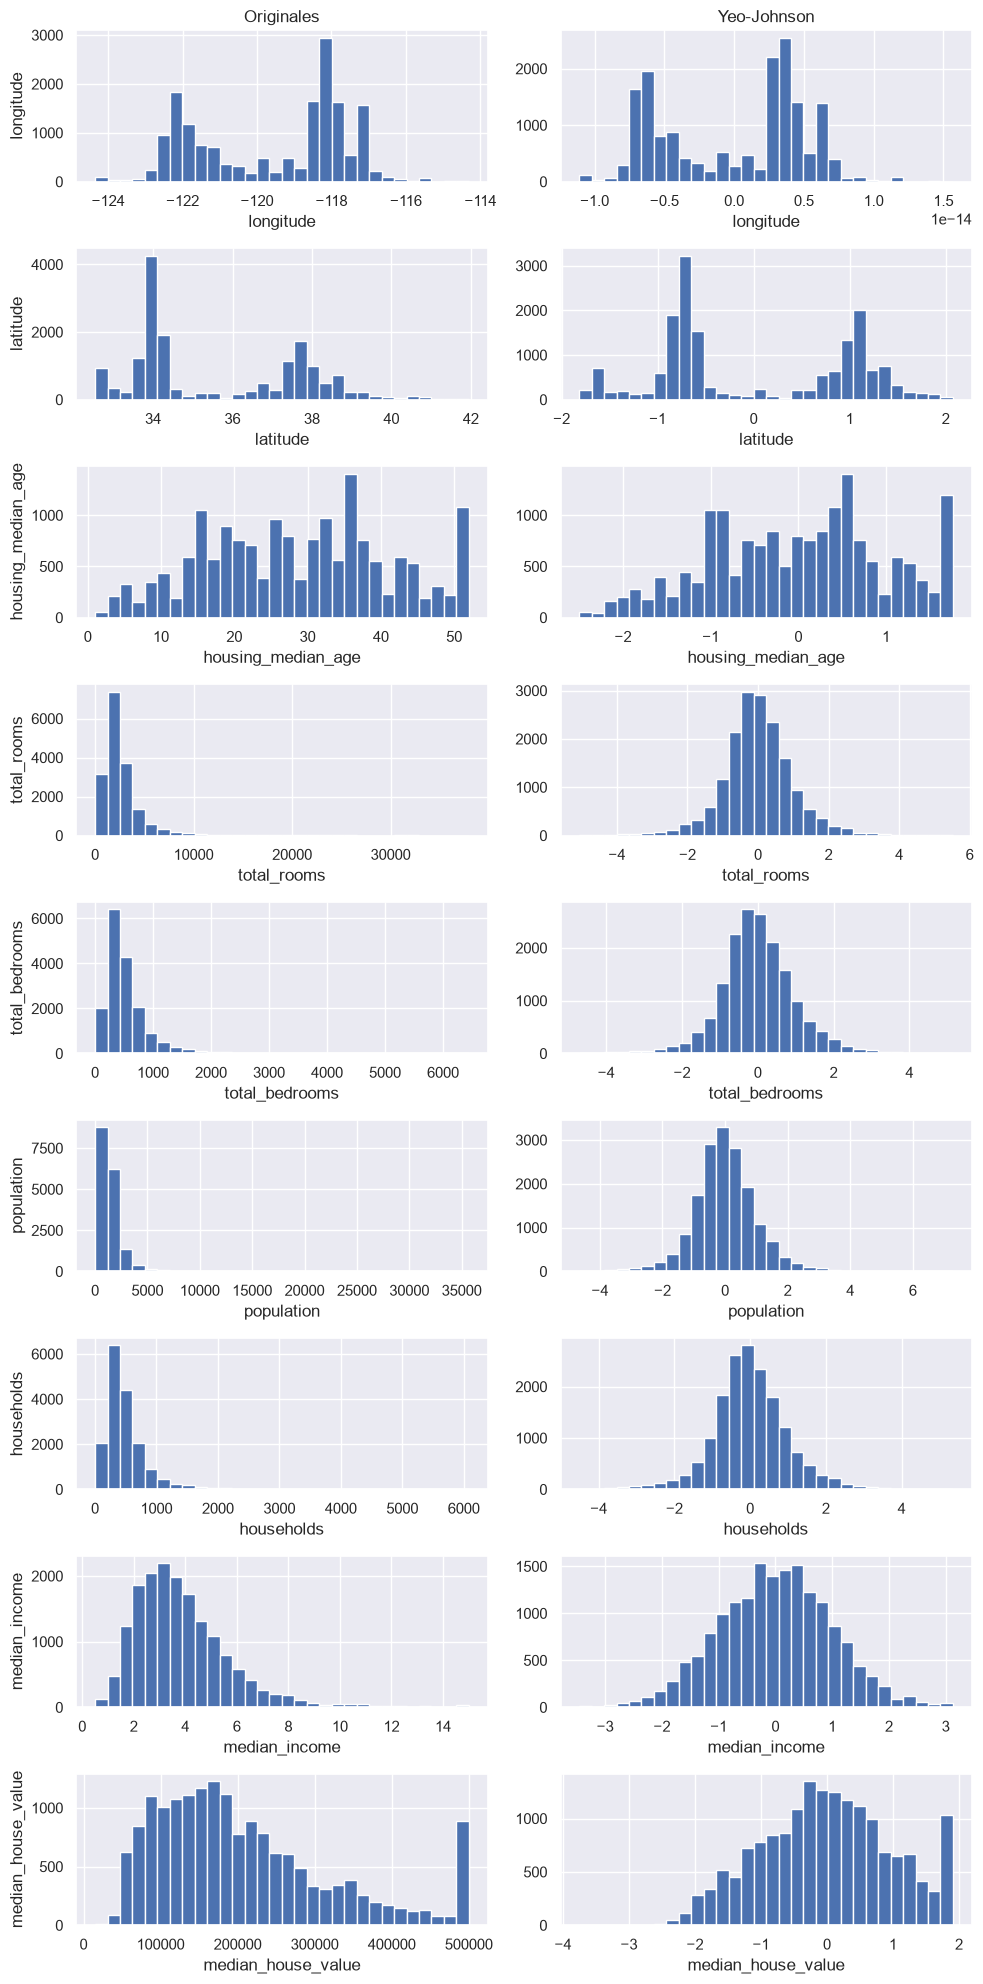

In [9]:
# NO DEBES MODIFICAR EL CóDIGO DE ESTA CELDA:

# Obtengamos los siguientes histogramas de los datos originales y sus transformaciones indicadas:

# Lista de las variables a transformar:
variables_a_transformar = ['longitude','latitude','housing_median_age','total_rooms',
                           'total_bedrooms','population','households','median_income',
                           'median_house_value']

yj = []  # para guardar las transformaciones obtenidas y usarlas más adelante con Pearson.

# Configuramos el entorno gráfico y mostramos los histogramas originales y los transformados:
sns.set(rc={'figure.figsize':(10,20)})
fig, axes = plt.subplots(len(variables_a_transformar),2)

for k in range(0, len(variables_a_transformar)):

    # Datos originales:
    Transf_originales = misdatos[variables_a_transformar[k]]

    plt.subplot(len(variables_a_transformar), 2, 2 * k + 1)
    plt.hist(Transf_originales, bins=30)
    plt.xlabel(variables_a_transformar[k])
    if k == 0:
        plt.title('Originales')
    plt.ylabel(variables_a_transformar[k]) # Esta es la etiqueta de cada variable.


    # Datos transformados con Yeo-Johnson:
    # La transformación .to_numpy().reshape(-1,1) es porque power_transform espera una entrada 2D
    Transf_yeojohnson = power_transform((Transf_originales.to_numpy()).reshape(-1,1), method ='yeo-johnson')
    yj.append(Transf_yeojohnson)

    plt.subplot(len(variables_a_transformar), 2, 2 * k + 2)
    plt.hist(Transf_yeojohnson, bins=30)
    plt.xlabel(variables_a_transformar[k])
    if k == 0:
        plt.title('Yeo-Johnson')

plt.tight_layout()
plt.show()

**Observa que las variables de entrada total_rooms, total_bedrooms, population y households, están claramente sesgadas positivamente. Y la variable de entrada median_income y la de salida median_house_value, un poco menos sesgadas.**



**PREGUNTAS:**

En los siguientes ejercicios supongamos que estamos analizando y preparando los datos para aplicar posteriormente un modelo de regresión lineal múltiple.

*   **Pregunta 1.1.** ¿Para qué se aplica usualmente la transformación Yeo-Johnson y cuál es su diferencia con Box-Cox?


*   **Pregunta 1.2.** ¿Cuál es la diferencia entre utilizar la métrica de la raíz cuadrada del error cuadrático medio RMSE (Root Mean Squared Error) y la del error absoluto medio MAE (Mean Absolute Error)? ¿Cuándo se recomienda utilizar cada uno?

*   **Pregunta 1.3.** Si vamos a aplicar posteriormente el modelo de regresión lineal múltiple y habiendo observado de los histogramas que las variables de entrada total_rooms, total_bedrooms, population, households y median_income tienen sesgos positivos ¿es recomendable aplicar alguna transformación de corrección de sesgo, como la mostrada de Yeo-Johnson en dichas variables? ¿Por qué?

*   **Pregunta 1.4.** Considerando ahora todas las variables de entrada de este problema, ¿es recomendable aplicarles alguna transformación de ajuste de escala (por ejemplo, la min-max, o la de normalización) antes de aplicar el modelo de regresión lineal múltiple? ¿Por qué?

*   **Pregunta 1.5.** Supongamos que ya decidiste aplicar la transformación Yeo-Johnson a las varibles sesgadas identificadas previamente. Una vez aplicada la Yeo-Johnson, ¿también es válido o recomendable aplicarles ahora una transformación de escala? ¿Por qué? En particular observa los histogramas resultantes con Yeo-Johnson obtenidos anteriormente para respaldar tu respuesta.

*   **Pregunta 1.6.** Supongamos que por alguna razón ya decidiste aplicar a las variables sesgadas tanto la transformación Yeo-Johnson, como la transformación de escala, ¿sería lo mismo aplicar primero la Yeo-Johnson seguida de la transformación de escala, que si lo hiciéramos al revés, es decir, primero la transformación de escala y luego la Yeo-Johnson? Justifica tu respuesta.

*   **Pregunta 1.7.** Observa ahora los histogramas de las variables de entrada originales "longitude" y "latitude". Claramente podríamos considerar a dichos histogramas como gráficos bimodales. ¿Qué se recomienda hacer en este caso? Es decir, ¿qué tipo de transformación o transformaciones se recomiendan aplicar? En particular, en este caso se observa que para estas variables la Yeo-Johnson no ayudó en absoluto.


*   **Pregunta 1.8.** Analicemos ahora la variable de salida median_house_value. ¿Cuál es ahora la recomendación para ajustar o transformar el sesgo o de corrección de escala? ¿Serían exactamente las mismas recomendaciones que se hicieron para las variables de entrada o se aplicaría un criterio diferente? Justifica tu respuesta.

*   **Pregunta 1.9.** Observa ahora el histograma de la variable de salida "median_house_value", ya sea la original o la transformada. Claramente se observa un "pico" al final de cualquiera de estos histogramas. ¿Qué transformación, criterio o recomendación adicional aplicaría para este tipo de gráficos?

### **Respuestas:**

*   **Respuesta 1.1.** La transformación Yeo-Johnson se aplica usualmente para reducir la asimetría (*skewness*) de una variable numérica, acercando su distribución a una normal, y de paso estabilizar la varianza y simplificar la relación entre esa variable y una variable respuesta. Esto es útil, por ejemplo, antes de aplicar modelos que asumen normalidad o varianza constante (como la regresión lineal).

    Su diferencia principal con Box-Cox está en el dominio de valores que acepta:

    *   **Box-Cox** solo funciona con valores estrictamente positivos ($x > 0$), ya que su fórmula requiere logaritmos y potencias no definidas para cero o negativos.
    *   **Yeo-Johnson** es una extensión de Box-Cox que también acepta cero y valores negativos, usando una definición por tramos ($x \geq 0$ y $x < 0$), lo que la hace más flexible en la práctica.

    Ambas dependen de un parámetro $\lambda$ que se estima (típicamente por máxima verosimilitud) para hallar la potencia óptima que mejor normaliza los datos.

    Ninguna de las dos transformaciones garantiza una normalidad perfecta; solo buscan aproximarse a ella, y su efectividad depende de qué tan sesgados estén los datos originales.

*   **Respuesta 1.2.**

    **RMSE (Root Mean Squared Error):** eleva al cuadrado cada error antes de promediarlos y luego saca la raíz cuadrada. Al elevar al cuadrado, los errores grandes pesan proporcionalmente mucho más que los pequeños, por lo que es una métrica sensible a valores atípicos y penaliza con mayor severidad las predicciones muy alejadas del valor real. Se recomienda usarla cuando los errores grandes son especialmente costosos o indeseables, por ejemplo, en aplicaciones donde una predicción muy desviada tiene consecuencias graves, ya que refleja esa penalización adicional sobre los errores extremos.

    **MAE (Mean Absolute Error):** promedia el valor absoluto de los errores, sin elevarlos al cuadrado, por lo que el error crece de forma lineal y todos los errores pesan proporcionalmente a su magnitud, sin sobrepenalizar los extremos. Esto la hace más robusta frente a valores atípicos y más fácil de interpretar como "el error absoluto promedio típico". Se recomienda usarla cuando se busca una medida de error más estable, menos dominada por unos pocos casos extremos, o cuando se quiere una interpretación directa y simple del error promedio.

    Ambas se expresan en las mismas unidades que la variable objetivo, lo que facilita su lectura práctica.

    **Diagnóstico adicional:** como $RMSE \geq MAE$ siempre, comparar ambas sirve como indicador de la dispersión de los errores: si RMSE es mucho mayor que MAE, hay errores grandes puntuales (valores atípicos) afectando el modelo; si son similares, los errores están distribuidos de forma más uniforme.

*   **Respuesta 1.3.**

    No es obligatorio transformar esas variables solo por tener sesgo positivo, ya que la regresión lineal no exige que los predictores sean normales; lo relevante es la linealidad de la relación con la respuesta y el comportamiento de los residuos (independencia, homocedasticidad, normalidad de errores).

    Yeo-Johnson conviene aplicarla solo si, tras ajustar el modelo, los residuos muestran problemas (no linealidad, heterocedasticidad, valores atípicos influyentes) que la transformación ayude a corregir, y siempre validando que mejora el desempeño (por ejemplo, RMSE/MAE). No debe aplicarse automáticamente, porque además cambia la interpretación de los coeficientes.

    El sesgo del histograma es una señal para investigar, no una razón suficiente para transformar; la decisión debe basarse en el diagnóstico de residuos y en la mejora real del modelo.

*   **Respuesta 1.4.** Para una regresión lineal ordinaria ajustada por mínimos cuadrados no suele ser indispensable escalar los predictores (`longitude`, `latitude`, `housing_median_age`, `total_rooms`, `total_bedrooms`, `population`, `households`, `median_income`): cambiar sus unidades no altera las predicciones ni el ajuste del modelo, aunque sí cambia la magnitud e interpretación de los coeficientes.

    Escalar (Min-Max o estandarización) es útil cuando se quieren comparar coeficientes entre variables, hay problemas numéricos de mal condicionamiento, o se usan métodos sensibles a la escala, especialmente regularización (Ridge, Lasso).

    La normalización por filas no equivale a escalar por columna y no es apropiada aquí, pues alteraría las proporciones entre las características de cada vivienda.

*   **Respuesta 1.5.** Sí, es válido aplicar una transformación de escala después de Yeo-Johnson; son operaciones distintas y pueden complementarse, aunque escalar no es un requisito universal para la regresión lineal ordinaria.

    *   **Yeo-Johnson** busca corregir la forma de la distribución (el sesgo), acercándola a una normal, pero no garantiza por sí sola que las variables queden en un rango común. Cada variable parte de una escala distinta y puede tener un parámetro $\lambda$ diferente.
    *   **El escalado** (estandarización o Min-Max) es una transformación lineal que cambia la ubicación y la escala de los valores, pero conserva la asimetría; no deshace el ajuste de forma ya realizado.

    En el ejercicio presentado se usó `power_transform` de scikit-learn, que aplica Yeo-Johnson y, por defecto (`standardize=True`), estandariza también el resultado. Por ello, los histogramas mostrados ya corresponden a datos transformados y estandarizados: quedan centrados y con una escala comparable. No se invocó por separado un `StandardScaler`, pero el paso de estandarización ya está incorporado.

    En consecuencia, aplicar después otra estandarización suele ser redundante. Se podría usar Min-Max si un método posterior requiere específicamente un rango como $[0,1]$. Cualquier transformación debe ajustarse con los datos de entrenamiento y luego aplicarse a validación y prueba para evitar fuga de información.

*   **Respuesta 1.6.** No es lo mismo; el orden sí importa, porque las dos transformaciones actúan de forma distinta sobre los datos:

    *   **Yeo-Johnson** es una transformación no lineal por tramos (para $x \geq 0$ y $x < 0$) cuyo parámetro óptimo $\lambda$ se estima a partir de los valores de entrada para buscar una distribución más cercana a la normal.
    *   **El escalado** (Min-Max o estandarización) es una transformación afín que desplaza y reescala los datos. Por sí solo, normalmente conserva la asimetría, aunque sí cambia la ubicación y la magnitud de los valores.

    **Yeo-Johnson seguida del escalado:** $\lambda$ se estima usando los valores originales. Después, el escalado cambia su ubicación o rango, pero no deshace la transformación de potencia ya aplicada. En `power_transform`, además, `standardize=True` por defecto ya estandariza la salida de Yeo-Johnson.

    **Escalado seguido de Yeo-Johnson:** el cambio de ubicación y escala previo puede modificar la distribución usada para estimar $\lambda$. Si el escalado desplaza valores a través de cero (por ejemplo, al centrar o al llevarlos al intervalo $[0,1]$), también puede cambiar qué valores se procesan con cada rama de Yeo-Johnson. Por eso el parámetro y el resultado pueden diferir de los obtenidos al transformar primero.

    En síntesis, las operaciones no conmutan en general. Como orden práctico, se suele ajustar Yeo-Johnson con los datos de entrenamiento y luego escalar, si el modelo lo requiere; todas las etapas deben ajustarse dentro del flujo de entrenamiento para evitar fuga de información.

*   **Respuesta 1.7.** Los histogramas muestran que `longitude` y `latitude` conservan dos picos tanto antes como después de Yeo-Johnson; en estos datos, la transformación cambia la escala, pero no elimina la bimodalidad observada. Yeo-Johnson es una transformación monótona: conserva el orden de las observaciones y está diseñada principalmente para corregir asimetría, no para combinar grupos distintos. Los picos pueden reflejar subpoblaciones geográficas reales, por ejemplo, zonas densamente pobladas de California, y no necesariamente un problema de sesgo que deba corregirse.

    **Recomendación:** no forzar una transformación de potencia en estas coordenadas; es preferible representar la información geográfica de manera más adecuada, por ejemplo:

    *   **Clustering espacial**, como K-means sobre `latitude` y `longitude`, para crear una variable de zona.
    *   **Variables derivadas**, como la distancia a ciudades principales.
    *   **Términos de interacción o no lineales**, como `latitude * longitude` o términos polinomiales.
    *   **Modelos no lineales**, como árboles de decisión o bosques aleatorios, si la estructura geográfica es importante y una regresión lineal pura no la representa adecuadamente.

*   **Respuesta 1.8.** Para `median_house_value` el criterio puede ser distinto al de los predictores, porque es la variable objetivo y la transformación cambia la escala en la que se ajustan los errores. Una distribución sesgada no implica por sí sola que el modelo vaya a cometer errores mayores en las viviendas caras; hay que revisar los residuos frente a los valores predichos y evaluar el modelo en validación. Si se observa una relación no lineal o varianza no constante, puede probarse una transformación como logaritmo (si los valores son positivos) o Yeo-Johnson, y confirmar que mejora el desempeño.

    En la práctica:

    1. Se puede transformar el objetivo antes de entrenar para intentar linealizar su relación con los predictores o estabilizar la varianza de los errores.
    2. El modelo se ajusta en la escala transformada; por ello, minimiza errores en esa escala, no directamente en dólares.
    3. Después de predecir, se aplica la transformación inversa para regresar a dólares. Las métricas que se quieran comunicar en unidades monetarias, como MAE o RMSE, deben calcularse sobre esas predicciones ya invertidas. La inversión puede introducir sesgo, por lo que conviene evaluar también la calibración de las predicciones.
    4. Los coeficientes corresponden a la escala transformada y no representan directamente cambios en dólares.

    Escalar el objetivo con Min-Max o estandarización no suele ser necesario para mínimos cuadrados ordinarios, aunque puede hacerse si el procedimiento lo requiere, siempre invirtiendo luego esa escala. En suma, una transformación del objetivo puede ser útil, pero debe elegirse a partir del diagnóstico de residuos y validarse; no es obligatoria solo porque el histograma esté sesgado.

*   **Respuesta 1.9.** El pico en el extremo superior de `median_house_value` es compatible con un tope impuesto al recolectar o publicar el conjunto: muchos valores quedan registrados en 500,001 aunque el valor real pudiera ser mayor. Esto es censura o *top-coding*, no un problema que Yeo-Johnson o un escalador puedan resolver. Se debe reconocer y documentar el límite; según el objetivo, se puede usar un método para respuestas censuradas, analizar por separado las observaciones afectadas o realizar análisis de sensibilidad. No se deben eliminar esos registros ni asignarles valores mayores arbitrariamente sin una justificación.

# **Ejercicio - 2: Matriz de Correlación de Pearson**

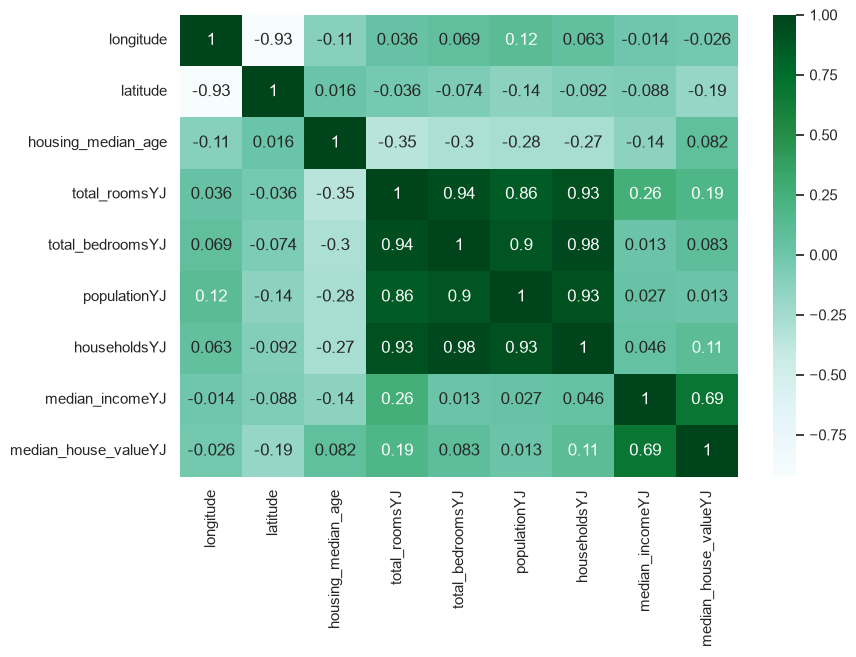

In [10]:
# NO DEBES MODIFICAR EL CóDIGO DE ESTA CELDA:

# Supongamos que obtenemos la matriz de correlación de Pearson, pero a las variables
# indicadas con YJ se les aplica ajuste de sesgo con Yeo-Johnson:
variables = ['longitude', 'latitude', 'housing_median_age', 'total_roomsYJ',
             'total_bedroomsYJ', 'populationYJ', 'householdsYJ', 'median_incomeYJ',
             'median_house_valueYJ']

# Creamos un nuevo DataFrame para almacenar las variables transformadas:
df_procesado = pd.DataFrame()

for var in variables:
    if var.endswith('YJ'):
        # Identificamos las variables del DataFrame origial a las cuales les aplicaremos Yeo-Johnson:
        col_origen = var if var in misdatos.columns else var[:-2]

        # Aplicamos la transformación Yeo-Johnson.
        # Usamos doble corchete ya que la función power_transform requiere un array 2D:
        df_procesado[var] = power_transform(misdatos[[col_origen]], method='yeo-johnson')
    else:
        # Las variables que no terminan en 'YJ' se copian directamente de los datos originales.
        df_procesado[var] = misdatos[var]

# Obtenemos la matriz de correlación de Pearson:
matriz_correlacion = df_procesado.corr(method='pearson')

sns.set(rc={'figure.figsize':(9,6)})
sns.heatmap(matriz_correlacion, annot=True, cmap='BuGn' )
plt.show()

**PREGUNTAS:**

*   **Pregunta 2.1.** ¿A qué tipo de variables (numéricas o categóricas) se aplica la matriz de correlación Pearson? ¿Y cuál es el objetivo de obtener dicha matriz?

*   **Pregunta 2.2.** Con respecto a la variable de salida, ¿qué variables de entrada están mayormente correlacionadas con ella? ¿Tiene sentido dentro del contexto y significado de las variables del problema?

*   **Pregunta 2.3.** En particular ¿cómo explicas el valor de correlación obtenido del factor "longitude" con respecto a la variable de salida transformada?

*   **Pregunta 2.4.** ¿Y cómo explicas el valor de correlación obtenido del factor "latitude" con respecto a la variable de salida transformada? ¿Tiene sentido con respecto al significado del problema?

*   **Pregunta 2.5.** Observa que con respecto a las variables de entrada y el concepto de multicolinealidad, varias de ellas tienen un alto valor de correlación de Pearson, ¿qué decisiones podemos tomar ahora con respecto a dichas variables?

### **Respuestas:**

*   **Respuesta 2.1.** La correlación de Pearson normalmente se aplica a normalmente a variables numéricas, idealmente continuas, y mide la fuerza y dirección de su asociación entre ellas, con valores entre −1 y 1. Puede ayudar a explorar relaciones entre variables y detectar predictores redundantes o posibles problemas de multicolinealidad. No es apropiada para categorías nominales codificadas con números, porque esos códigos no representan distancias cuantitativas; para ellas se requieren otras medidas de asociación. En resumen nos ayuda a que ver que variable esta mas relacionada con la variable que se quiere predecir.

*   **Respuesta 2.2.** Según la matriz, la variable de entrada con mayor correlación lineal con `median_house_valueYJ` es `median_incomeYJ` (r ≈ 0.69), una asociación positiva relativamente fuerte. Le siguen `total_roomsYJ` (r ≈ 0.19) y `latitude` (r ≈ −0.19). Tiene sentido que el ingreso mediano del área se asocie con el precio de las viviendas; las relaciones con habitaciones y ubicación también pueden ser relevantes, pero su correlación lineal marginal es mucho menor. Correlación no implica causalidad y tampoco describe por sí sola relaciones no lineales o condicionadas por otras variables.

*   **Respuesta 2.3.** `longitude` tiene una correlación prácticamente nula con la salida (r ≈ −0.026). Esto no significa que la ubicación no importe o no sea reelevante: el valor de las viviendas puede variar de manera no lineal y distinta entre las distintas zonas por ejemplo costetas, ciudades y regiones interiores de california. Al resumir toda California en una sola correlación lineal, el resultado del valor puede compensarse con diferentes regiones. Conviene analizar la ubicación junto con `latitude`, visualizar los datos geográficamente o probar términos espaciales/no lineales.

*   **Respuesta 2.4.** `latitude` presenta una correlación negativa débil con `median_house_valueYJ` (r ≈ −0.19): en promedio, valores más al norte se asocian ligeramente con valores menores en esta medida lineal. Se puede dar el caso en donde esta relacion refleje diferencias regionales, pero no una regla uniforme en todo el estado; existen áreas costosas en distintas latitudes no solo en el sur. Por eso la coordenada debe interpretarse como parte de un patrón geográfico complejo, no como un efecto aislado ni causal.

*   **Respuesta 2.5.** Hay correlaciones altas entre varios caracteristicas de la vivienda como: `total_roomsYJ`,`total_bedroomsYJ`, `populationYJ` y `householdsYJ`En sus diferentes combinaciones. Esta redundancia puede dificultar la estabilidad y la interpretación de los coeficientes de una regresión lineal, aunque no necesariamente perjudica las predicciones. Se puede seleccionar, eliminar redundantes o combinar variables según su significado, comparar modelos con validación cruzada. No conviene eliminar variables solo por su correlación y sin una justificacion de duplicidad: la decisión debe basarse en el objetivo, la interpretación y el desempeño validado.

# **Ejercicio - 3: Conclusiones Finales**

**En particular, cuando hayas usado algún LLM, comenta qué tanto cambiaste a personalizaste las respuestas. Por ejemplo: ¿usaste todo el texto que te proporcionó o solo algunas partes?; ¿complementaste con varios LLM para cada respuesta? ¿Le hiciste preguntas adicionales, después de la primera?**



++++++++ Incluye a continuación tus conclusiones finales de la actividad ++++++++++++++++++++++++++

Esta actividad me sirvió para reforzar los conceptos aprendidos en el curso de Analítica de Datos y aplicarlos en un caso práctico. El ejercicio me permitió analizar cómo preparar los datos antes de ajustar un modelo de regresión lineal, con el propósito de obtener resultados adecuados. Aunque ya conocía varios de los conceptos y su aplicación gracias a las lecturas de apoyo, recurrí a un modelo de lenguaje (LLM) para profundizar en mis respuestas y ampliar mis conocimientos sobre el tema.

Utilicé ChatGPT 5.6 Terra para investigar algunos términos que no tenía tan presentes y redactar mis respuestas. Después, le pedí que me ayudara a complementarlas y a validar mis planteamientos. Cuando encontré alguna discrepancia, profundicé en el tema para comprender las razones y formular una conclusión mejor fundamentada.

**Bibliografía:**

* OpenAI. (2026). ChatGPT (versión GPT-5.6 Terra) [Modelo de lenguaje de gran tamaño]. https://chat.openai.com/
* Géron, A. (2022). Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow (3.ª ed.). O'Reilly Media.

++++++++ Termina sección para agregar texto ++++++++++++++++++++++++

# **<< Fin de la Actividad de la Semana 2 - California Housing>>**